In [1]:
import astropy.units as u
import numpy as np
from astropy.io import ascii

import naima
from naima.models import ExponentialCutoffPowerLaw, Synchrotron

data = ascii.read("data2.ecsv")

def sync(pars, data):
    """
    Define particle distribution model, radiative model, and return model flux
    at data energy values
    """
    amplitude = pars[0] / u.eV
    e_cutoff = (10**pars[1]) * u.TeV
    B_source = pars[2] * u.uG

    ECPL = ExponentialCutoffPowerLaw(amplitude, 1*u.TeV, 2.0, e_cutoff)
    Syn = Synchrotron(ECPL, B=B_source, Eemin = 100*u.MeV)

    # Save this realization of the particle distribution function
    elec_energy = np.logspace(8, 14, 100) * u.eV
    nelec = ECPL(elec_energy)
    
    # The first array returned will be compared to the observed spectrum for
    # fitting. All subsequent objects will be stores in the sampler metadata
    # blobs.
    
    return Syn.flux(data, distance=1.0*u.kpc), (elec_energy, nelec)

def lnprior(pars):
    # Limit amplitude and B to positive domain
    lnprior = naima.uniform_prior(pars[0], 0., np.inf) \
            + naima.uniform_prior(pars[1], -2, 3) \
            + naima.uniform_prior(pars[2], 1.0, 1000.0)
    return lnprior

In [2]:
#def sync(pars, data):
#    """
#    Define particle distribution model, radiative model, and return model flux
#    at data energy values
#    """
#    pars --> system_parameters.f90? 
#    make, run.x --> 'flujos.dat'
#    flujos --> read (flujos.dat), interpolar en valores (data, flujos(data))
#
#    return flujos

In [3]:
## Set initial parameters and labels
p0 = np.array((1e32, np.log10(12), 120.0))
labels = ["norm", "log10(cutoff)", "B[uG]"]

In [4]:
## Run sampler
sampler, pos = naima.run_sampler(
    data_table=data,
    p0=p0,
    labels=labels,
    model=sync,
    prior=lnprior,
    nwalkers=32,
    nburn=30,
    nrun=10,
    threads=4,
    prefit=True,
    interactive=False,
)

INFO: Finding Maximum Likelihood parameters through Nelder-Mead fitting... [naima.core]
INFO:    Initial parameters: [7.62514020e+27 1.07918125e+00 1.20000000e+02] [naima.core]
INFO:    Initial lnprob(p0): -128730.264 [naima.core]
INFO:    New ML parameters : [1.53800455e+28 3.47452689e-01 1.83396928e+02] [naima.core]
INFO:    Maximum lnprob(p0): -1.753 [naima.core]
Burning in the 32 walkers with 30 steps...

Progress of the run: 0 percent (0 of 30 steps)
                           -----norm------ -log10(cutoff)- -----B[uG]-----
  Last ensemble median :    1.54e+28          0.347            184      
  Last ensemble std    :    9.88e+25         0.00198          1.33      
  Last ensemble lnprob :  avg: -1.804, max: -1.750

Progress of the run: 10 percent (3 of 30 steps)
                           -----norm------ -log10(cutoff)- -----B[uG]-----
  Last ensemble median :    1.54e+28          0.348            184      
  Last ensemble std    :    2.84e+26         0.00892          2.99     

In [5]:
## Save run results to HDF5 file (can be read later with naima.read_run)
naima.save_run("prueba.hdf5", sampler)

In [6]:
## Diagnostic plots with labels for the metadata blobs
naima.save_diagnostic_plots(
    "prueba",
    sampler,
    sed=True,
    last_step=False,
    blob_labels=[
        "Spectrum",
        "Electron energy distribution",
    ],
)
naima.save_results_table("prueba", sampler)

INFO: Plotting chain of parameter norm... [naima.analysis]
INFO: -----------------------norm-----------------------
          norm = $(1.52^{+0.18}_{-0.14})\times10^{28}$ [naima.plot]
INFO: Plotting chain of parameter log10(cutoff)... [naima.analysis]
INFO: ------------------log10(cutoff)-------------------
          log10(cutoff) = $0.342^{+0.02}_{-0.016}$
                 cutoff = $2.20^{+0.12}_{-0.08}$ [naima.plot]
INFO: Plotting chain of parameter B[uG]... [naima.analysis]
INFO: ----------------------B[uG]-----------------------
          B[uG] = $185^{+8}_{-17}$ [naima.plot]
INFO: Plotting corner plot... [naima.analysis]
INFO: Plotting Spectrum... [naima.analysis]


/home/santiagodp/anaconda3/lib/python3.8/site-packages/naima/analysis.py:160: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  f.clf()


INFO: Plotting Electron energy distribution... [naima.analysis]
INFO: Saving results table in prueba_results.ecsv [naima.analysis]


label,median,unc_lo,unc_hi
bytes72,float64,float64,float64
norm,1.519217811905559e+28,1.3832421104343423e+27,1.803627798825479e+27
log10(cutoff),0.3424558547901022,0.01596251485516126,0.023464085620195696
cutoff,2.200168361595731,0.07939947550046478,0.12214029159207396
B[uG],184.65106763889554,16.752488784023882,7.724330136065021


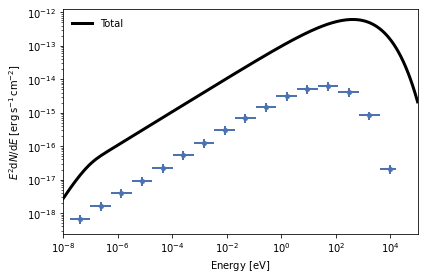

In [7]:
p1 = np.array((1.18e+30, 9.65, 99.39))
#p1 = np.array((1.2e+30, 10.0, 100.0))


# Use plot_data from naima to plot the observed spectra
figure = naima.plot_data(data, e_unit=u.eV)
ax = figure.axes[0]

ECPL = ExponentialCutoffPowerLaw(p1[0] / u.eV, 1*u.TeV, 2.0, p1[1] * u.TeV)
SYN = Synchrotron(ECPL, B=p1[2] * u.uG, Eemin = 100 * u.MeV)

# Plot the computed model emission
energy = np.logspace(-8, 5, 150) * u.eV
ax.loglog(
    energy,
    SYN.sed(energy, 1 * u.kpc),
    lw=3,
    c="k",
    label="Total",
)

ax.set_xlim(1e-8, 1e5)
ax.legend(loc="best", frameon=False)
figure.tight_layout()
figure.savefig("prueba_SED.png")

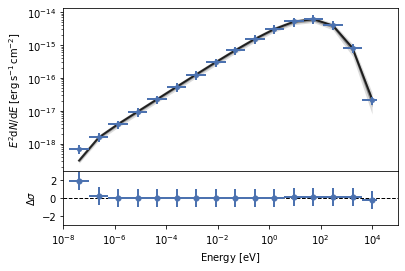

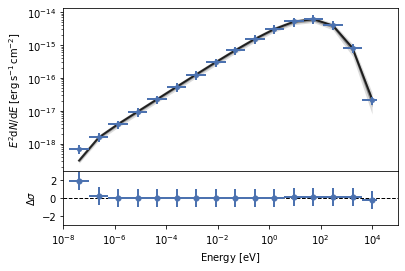

In [8]:
naima.plot_fit(sampler, confs=[3,1])